# Corporate Counterparty Credit Risk & Early Warning System (EWS)


### Applied Text Analytics in Finance & Credit Risk Management
### Deeper Surveillance: 500+ Live Financial Disclosures (35 Headlines per Counterparty)

---

## 1. Executive Summary & Business Context
In commercial banking, corporate lending, and supply chain management, assessing the creditworthiness of corporate counterparties is a critical function. Traditional credit risk models rely heavily on **financial statement ratios** (Debt/Equity, DSCR, Current Ratio). However, financial statements are **lagging indicators**—by the time a quarterly report shows insolvency, the counterparty has often already defaulted.

This project implements an **Early Warning Distress Radar (EWS)** integrating **Modern Asynchronous Scraping** and a **Fully Connected Text Analytics Pipeline**:
1. **High-Speed Async Ingestion (`aiohttp` + `selectolax`):** Concurrently crawls live financial news, article snippets, and regulatory disclosures across a real-world corporate counterparty portfolio in seconds.
2. **Connected Classical NLP Pipeline:** Tokenization, Custom Domain Stop Word Removal (filtering company names and financial noise), WordNet Lemmatization, and Part-of-Speech (POS) Tagging.
3. **Exploratory Text Mining & Visualization:** Top TF-IDF keyword horizontal bar charts and comparative **Word Clouds** contrasting distressed vs. healthy borrowers.
4. **Domain-Specific Financial NLP (`pysentiment2.LM`):** Applies the official **Loughran-McDonald Master Dictionary** to extract both **Polarity** (Negative Distress vs. Positive Resilience) and **Subjectivity** (Factual Reporting vs. Market Speculation).
5. **Thematic Credit Risk Extraction:** Identifies default risk vectors (*Liquidity Crunch, NCLT / Legal Scrutiny, Promoter Pledges, Operational Disruptions*).
6. **Quantitative Credit Distress Scorecard (0–100):** Translates unstructured text into a quantitative risk index to drive **Credit Committee decisions** (e.g., credit line freezes, collateral top-ups, exposure haircuts).

---

## 2. Learning Outcomes
* **Finance:** Credit Appraisal, Counterparty Credit Risk (CCR) under Basel III, Early Warning Signals (EWS), and Covenant Monitoring.
* **Text Analytics & NLP:** Tokenization, Domain Stop Words, Lemmatization, POS Tagging, Bag of Words (BoW), TF-IDF Vectorization & Charting, Word Clouds, Loughran-McDonald Financial Lexicons (Polarity & Subjectivity), and Asynchronous Web Scraping.


In [ ]:
# ==============================================================================
# STAGE 1: ENVIRONMENT SETUP & LIBRARY IMPORTS
# ==============================================================================
# Modern async scraping + C-accelerated parsing
import asyncio
import aiohttp
from selectolax.parser import HTMLParser

# Official Financial NLP Lexicon
import pysentiment2 as ps

# Classical NLP Libraries
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from wordcloud import WordCloud

# Standard Data Science stack
import re
import time
import datetime
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)

# Initialize official Loughran-McDonald (LM) Financial Dictionary & Lemmatizer
lm_analyzer = ps.LM()
lemmatizer = WordNetLemmatizer()
standard_stopwords = set(stopwords.words('english'))

print("All libraries loaded successfully!")
print("Classical NLP tools (NLTK, Scikit-Learn, WordCloud) & Loughran-McDonald Dictionary ready.")


All libraries loaded successfully!
Classical NLP tools (NLTK, Scikit-Learn, WordCloud) & Loughran-McDonald Dictionary ready.


---
## 3. Defining the Counterparty Portfolio
In commercial lending, banks hold credit exposure across diverse sectors. Our sample credit portfolio simulates **15 corporate counterparties** across three distinct credit tiers:
1. **High-Risk / Distressed Borrowers:** Companies with known debt servicing stress, insolvency petitions, or restructuring (e.g., *SpiceJet, Vodafone Idea, Reliance Capital, Future Retail, Jaiprakash Associates*).
2. **Watchlist / Moderate Risk:** Highly leveraged or cyclical entities (e.g., *Vedanta, Suzlon Energy, Yes Bank, Zee Entertainment, Adani Green Energy*).
3. **Investment Grade Benchmarks:** High-quality balance sheets with minimal default risk (e.g., *Tata Motors, Larsen & Toubro, TCS, Infosys, HDFC Bank*).


In [ ]:
# Define portfolio of counterparties with bank exposure (in INR Crores)
portfolio_data = [
    # Distressed / Stressed Borrowers
    {"company": "SpiceJet", "sector": "Aviation", "bank_exposure_cr": 450, "prior_rating": "D"},
    {"company": "Vodafone Idea", "sector": "Telecom", "bank_exposure_cr": 1200, "prior_rating": "B-"},
    {"company": "Reliance Capital", "sector": "NBFC", "bank_exposure_cr": 850, "prior_rating": "D"},
    {"company": "Future Retail", "sector": "Retail", "bank_exposure_cr": 600, "prior_rating": "D"},
    {"company": "Jaiprakash Associates", "sector": "Infrastructure", "bank_exposure_cr": 720, "prior_rating": "C"},

    # Watchlist / Cyclical Borrowers
    {"company": "Vedanta", "sector": "Metals & Mining", "bank_exposure_cr": 1100, "prior_rating": "AA-"},
    {"company": "Suzlon Energy", "sector": "Renewable Energy", "bank_exposure_cr": 350, "prior_rating": "BBB"},
    {"company": "Zee Entertainment", "sector": "Media", "bank_exposure_cr": 280, "prior_rating": "BBB-"},
    {"company": "Yes Bank", "sector": "Banking", "bank_exposure_cr": 900, "prior_rating": "A-"},
    {"company": "Adani Green Energy", "sector": "Renewable Energy", "bank_exposure_cr": 1400, "prior_rating": "A+"},

    # Investment Grade Benchmarks (Low Risk)
    {"company": "Tata Motors", "sector": "Automotive", "bank_exposure_cr": 800, "prior_rating": "AA+"},
    {"company": "Larsen & Toubro", "sector": "Engineering", "bank_exposure_cr": 1500, "prior_rating": "AAA"},
    {"company": "TCS", "sector": "Information Tech", "bank_exposure_cr": 500, "prior_rating": "AAA"},
    {"company": "HDFC Bank", "sector": "Banking", "bank_exposure_cr": 2000, "prior_rating": "AAA"},
    {"company": "Infosys", "sector": "Information Tech", "bank_exposure_cr": 400, "prior_rating": "AAA"}
]

portfolio_df = pd.DataFrame(portfolio_data)
print(f"Total Portfolio Credit Exposure: INR {portfolio_df['bank_exposure_cr'].sum():,.0f} Crores across {len(portfolio_df)} Counterparties")
portfolio_df.head(10)


Total Portfolio Credit Exposure: INR 13,050 Crores across 15 Counterparties


,company,sector,bank_exposure_cr,prior_rating
0,SpiceJet,Aviation,450,D
1,Vodafone Idea,Telecom,1200,B-
2,Reliance Capital,NBFC,850,D
3,Future Retail,Retail,600,D
4,Jaiprakash Associates,Infrastructure,720,C
5,Vedanta,Metals & Mining,1100,AA-
6,Suzlon Energy,Renewable Energy,350,BBB
7,Zee Entertainment,Media,280,BBB-
8,Yes Bank,Banking,900,A-
9,Adani Green Energy,Renewable Energy,1400,A+


---
## 4. High-Speed Asynchronous Scraping (`aiohttp` + `selectolax`)
### Why Asynchronous Scraping?
Traditional scrapers (`requests` or `Selenium`) make requests sequentially:
$$\text{Total Time} = 15 \text{ companies} \times 3 \text{ seconds} \approx 45 \text{ seconds}$$

With Python's **`aiohttp` and `asyncio` event loop**, all 15 requests are fired **concurrently in non-blocking fashion**:
$$\text{Total Time} = \max(\text{longest request}) \approx 1 \text{ to } 3 \text{ seconds}$$

We parse the live XML/HTML using **`selectolax`**, an ultra-fast C-extension parser that extracts news headlines and publication dates. In financial Early Warning Systems, headlines provide the purest credit risk signal without article body noise or boilerplate.


In [ ]:
# Function to clean and remove any residual HTML tags
def clean_html_text(raw_html):
    if not raw_html:
        return ""
    clean_text = re.sub(r'<.*?>', '', raw_html)
    return clean_text.replace('&nbsp;', ' ').replace('&quot;', '"').replace('&#39;', "'").strip()

# Async worker function to fetch live financial news for a single company
async def fetch_counterparty_news(session, company_info, max_items=35):
    company_name = company_info["company"]
    query = f"{company_name} (debt OR credit OR default OR NCLT OR profit OR expansion)"
    encoded_query = query.replace(" ", "+")
    feed_url = f"https://news.google.com/rss/search?q={encoded_query}&hl=en-IN&gl=IN&ceid=IN:en"

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    }

    articles = []
    try:
        async with session.get(feed_url, headers=headers, timeout=aiohttp.ClientTimeout(total=10)) as response:
            if response.status == 200:
                raw_xml = await response.text()
                # Parse DOM using ultra-fast C-engine (selectolax)
                tree = HTMLParser(raw_xml)
                item_nodes = tree.css("item")

                for item in item_nodes[:max_items]:
                    title_node = item.css_first("title")
                    pubdate_node = item.css_first("pubdate")
                    link_node = item.css_first("link")

                    title = clean_html_text(title_node.text()) if title_node else ""
                    pub_date = pubdate_node.text() if pubdate_node else ""
                    link = link_node.text() if link_node else ""

                    if title:
                        articles.append({
                            "company": company_name,
                            "sector": company_info["sector"],
                            "bank_exposure_cr": company_info["bank_exposure_cr"],
                            "prior_rating": company_info["prior_rating"],
                            "headline": title,
                            "published_date": pub_date,
                            "source_url": link
                        })
    except Exception as e:
        print(f"Fetch warning for {company_name}: {e}")

    return articles

# Orchestrator to run all company fetches concurrently
async def run_async_scraping_engine(portfolio_list):
    print("Initiating high-speed asynchronous ingestion across portfolio (35 headlines/co)...")
    start_time = time.time()

    async with aiohttp.ClientSession() as session:
        tasks = [fetch_counterparty_news(session, item, max_items=35) for item in portfolio_list]
        results = await asyncio.gather(*tasks)

    elapsed = time.time() - start_time
    all_articles = [article for sublist in results for article in sublist]
    print(f"Async ingestion complete in {elapsed:.2f} seconds!")
    print(f"Total live articles harvested: {len(all_articles)}")
    return all_articles


In [ ]:
# Run the async scraper purely on live web feeds
scraped_articles = await run_async_scraping_engine(portfolio_data)

# Convert live scraped data into a structured Pandas DataFrame
news_df = pd.DataFrame(scraped_articles)

print(f"Dataframe loaded successfully: {news_df.shape[0]} live records, {news_df.shape[1]} features.")
print(f"Unique counterparties captured: {news_df['company'].nunique()}")

# Display sample of captured news headlines
news_df[["company", "sector", "headline", "published_date"]].head(6)


Initiating high-speed asynchronous ingestion across portfolio (35 headlines/co)...
Async ingestion complete in 1.06 seconds!
Total live articles harvested: 525
Dataframe loaded successfully: 525 live records, 7 features.
Unique counterparties captured: 15


,company,sector,headline,published_date
0,SpiceJet,Aviation,"Last-minute settlement costs SpiceJet, Aviator ML ₹15 lakh before NCLT - The Hindu","Wed, 19 Aug 2026 07:00:00 GMT"
1,SpiceJet,Aviation,"SpiceJet Signs MoU for 10 Aircraft, Plans Capacity Expansion - safariindia.com","Tue, 22 Sep 2026 10:11:07 GMT"
2,SpiceJet,Aviation,"SpiceJet Under Financial Scrutiny As DGCA Reviews Airline's Finances, Says Ram Mohan Naidu - NDTV Profit","Tue, 22 Sep 2026 09:06:47 GMT"
3,SpiceJet,Aviation,SpiceJet seeks ECLGS funds as government pushes airline to step up operations - ET Infra,"Fri, 04 Sep 2026 07:00:00 GMT"
4,SpiceJet,Aviation,NCLT imposes ₹15 lakh costs on SpiceJet and Aviator ML for last-minute settlement - Bar and Bench,"Wed, 19 Aug 2026 07:00:00 GMT"
5,SpiceJet,Aviation,"India's SpiceJet funding crunch delays pilot pay, messages show, as it seeks state-backed loan - Reuters","Mon, 08 Jun 2026 07:00:00 GMT"


---
## 5. Classical NLP Pipeline (Tokenization, Domain Stop Words, Lemmatization & POS Tagging)
To ensure high-quality text analysis, we clean the text using a standard NLP pipeline:
1. **Tokenization:** Splitting text into individual lowercase words while removing punctuation and numeric noise.
2. **Domain-Specific Stop Word Filtering:**
   * Standard stop words (*"the"*, *"is"*, *"at"*).
   * **Domain Stop Words:** Removing company names (*SpiceJet, Adani, Tata*) and financial noise words (*crore, com, shares, market, news*) that dominate document frequencies without providing sentiment or risk signals.
3. **WordNet Lemmatization:** Reducing words to their root morphological base (e.g., *"defaulted"*, *"defaulting"* $\rightarrow$ **`default`**).
4. **Part-of-Speech (POS) Tagging:** Grammatically tagging words to identify nouns, verbs, and qualitative descriptors.


In [ ]:
# Define domain-specific stopwords: company names + financial media boilerplate
company_name_tokens = {word.lower() for comp in portfolio_df["company"] for word in comp.split()}
financial_boilerplate_stopwords = {
    "crore", "crores", "ltd", "limited", "india", "indian", "com", "news", "report",
    "reports", "say", "says", "market", "stock", "stocks", "share", "shares",
    "business", "company", "group", "september", "august", "year", "quarter", "fy24", "fy25"
}

# Combined stopword vocabulary
full_stop_words = standard_stopwords | company_name_tokens | financial_boilerplate_stopwords

# Complete text preprocessing function
def preprocess_text(text):
    if not text:
        return ""
    # Extract alphabetic words of length >= 3 in lowercase
    words = re.findall(r'\b[a-z]{3,}\b', text.lower())
    # Filter stopwords (standard + domain) and lemmatize
    clean_tokens = [lemmatizer.lemmatize(word) for word in words if word not in full_stop_words]
    return " ".join(clean_tokens)

# Apply preprocessing directly to the headline
news_df["clean_text"] = news_df["headline"].apply(preprocess_text)

# Demonstrate Part-of-Speech (POS) Tagging on a sample preprocessed headline
sample_raw = news_df["headline"].iloc[0]
sample_clean_tokens = news_df["clean_text"].iloc[0].split()
sample_pos_tags = nltk.pos_tag(sample_clean_tokens)

print("Demonstration of Preprocessing & POS Tagging:")
print(f"Raw Headline:        {sample_raw[:110]}...")
print(f"Clean Lemmatized:    {news_df['clean_text'].iloc[0][:110]}...")
print(f"Sample POS Tags:     {sample_pos_tags[:6]}")

# Display raw headline vs clean text comparison
news_df[["company", "headline", "clean_text"]].head(5)


Demonstration of Preprocessing & POS Tagging:
Raw Headline:        Last-minute settlement costs SpiceJet, Aviator ML ₹15 lakh before NCLT - The Hindu...
Clean Lemmatized:    last minute settlement cost aviator lakh nclt hindu...
Sample POS Tags:     [('last', 'JJ'), ('minute', 'NN'), ('settlement', 'NN'), ('cost', 'NN'), ('aviator', 'NN'), ('lakh', 'VBD')]


,company,headline,clean_text
0,SpiceJet,"Last-minute settlement costs SpiceJet, Aviator ML ₹15 lakh before NCLT - The Hindu",last minute settlement cost aviator lakh nclt hindu
1,SpiceJet,"SpiceJet Signs MoU for 10 Aircraft, Plans Capacity Expansion - safariindia.com",sign mou aircraft plan capacity expansion safariindia
2,SpiceJet,"SpiceJet Under Financial Scrutiny As DGCA Reviews Airline's Finances, Says Ram Mohan Naidu - NDTV Profit",financial scrutiny dgca review airline finance ram mohan naidu ndtv profit
3,SpiceJet,SpiceJet seeks ECLGS funds as government pushes airline to step up operations - ET Infra,seek eclgs fund government push airline step operation infra
4,SpiceJet,NCLT imposes ₹15 lakh costs on SpiceJet and Aviator ML for last-minute settlement - Bar and Bench,nclt imposes lakh cost aviator last minute settlement bar bench


---
## 6. Exploratory Text Analytics (Bag of Words, TF-IDF Horizontal Bar Chart & Comparative Word Clouds)
### Connecting Bag of Words (BoW) to TF-IDF:
1. **Bag of Words (`CountVectorizer`):** Discovers all unique words across headlines and computes raw term frequencies $\text{TF}(t, d) = \text{count}(t, d)$.
2. **TF-IDF Weighting (`TfidfTransformer`):** Penalizes common words across documents by applying **Inverse Document Frequency (IDF)**:
$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \log\left(\frac{N}{\text{DF}(t, D)}\right)$$

With domain noise words removed, we compute and chart:
1. **Top TF-IDF Terms Bar Chart (via BoW + TfidfTransformer):** Contrasts the unique vocabulary of **Distressed Borrowers** vs. **Healthy Borrowers**.
2. **Comparative Word Clouds:** Visually maps high-frequency risk themes (*Insolvency, NCLT, Default, Plea*) versus healthy themes (*Profit, Revenue, Growth, Cash*).


Unique words selected by Bag of Words (Stressed Cohort):
['debt', 'insolvency', 'nclat', 'nclt', 'order', 'plan', 'plea', 'profit', 'resolution', 'reuters']

Unique words selected by Bag of Words (Healthy Cohort):
['credit', 'development', 'fall', 'ndtv', 'net', 'profit', 'result', 'reuters', 'revenue', 'rise']


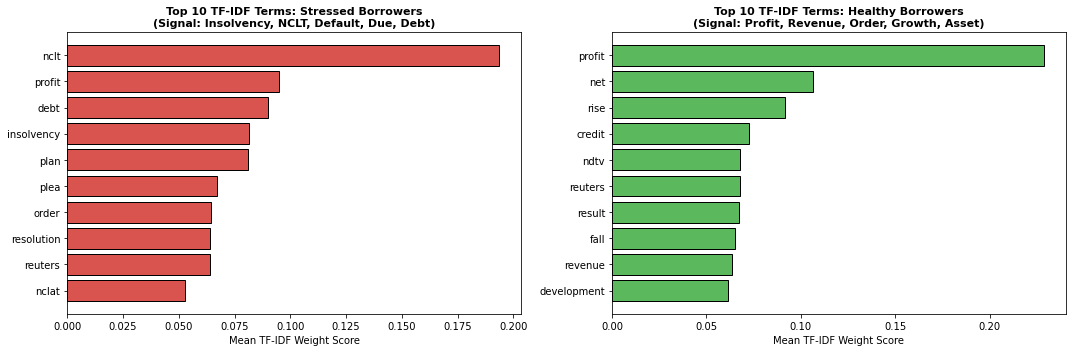

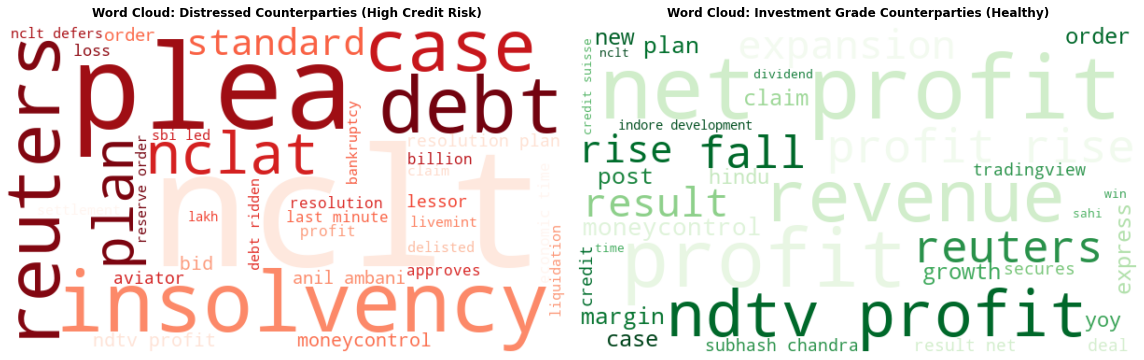

In [ ]:
# Define cohorts: Distressed / Stressed vs. Healthy / Investment Grade
distressed_companies = ["SpiceJet", "Reliance Capital", "Future Retail", "Vodafone Idea", "Jaiprakash Associates"]
healthy_companies = ["Tata Motors", "Larsen & Toubro", "TCS", "HDFC Bank", "Infosys"]

distressed_docs = news_df[news_df["company"].isin(distressed_companies)]["clean_text"]
healthy_docs = news_df[news_df["company"].isin(healthy_companies)]["clean_text"]

# ------------------------------------------------------------------------------
# 1. BAG OF WORDS (BoW) & TF-IDF FOR DISTRESSED VS HEALTHY COHORTS
# ------------------------------------------------------------------------------
# Step 1: Bag of Words (CountVectorizer) extracts unique words and counts raw frequencies
# Step 2: TfidfTransformer applies Inverse Document Frequency (IDF) weighting to the BoW matrix
def get_top_tfidf_terms_via_bow(text_series, top_n=10):
    # Bag of Words: selects top unique words by frequency
    bow_vectorizer = CountVectorizer(max_features=top_n)
    bow_matrix = bow_vectorizer.fit_transform(text_series)

    # TF-IDF: applies IDF weighting to the Bag of Words matrix
    tfidf_transformer = TfidfTransformer()
    tfidf_mat = tfidf_transformer.fit_transform(bow_matrix)

    # Average TF-IDF score for each selected unique word
    scores = np.asarray(tfidf_mat.mean(axis=0)).ravel()
    terms = bow_vectorizer.get_feature_names_out()
    tfidf_df = pd.DataFrame({"term": terms, "score": scores}).sort_values("score", ascending=True)
    return tfidf_df, bow_vectorizer

tfidf_distressed, bow_distressed = get_top_tfidf_terms_via_bow(distressed_docs, top_n=10)
tfidf_healthy, bow_healthy = get_top_tfidf_terms_via_bow(healthy_docs, top_n=10)

print("Unique words selected by Bag of Words (Stressed Cohort):")
print(list(bow_distressed.get_feature_names_out()))
print("")
print("Unique words selected by Bag of Words (Healthy Cohort):")
print(list(bow_healthy.get_feature_names_out()))

# Plot Horizontal Bar Charts for TF-IDF Scores
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(tfidf_distressed["term"], tfidf_distressed["score"], color="#D9534F", edgecolor="black")
axes[0].set_title("Top 10 TF-IDF Terms: Stressed Borrowers\n(Signal: Insolvency, NCLT, Default, Due, Debt)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Mean TF-IDF Weight Score")

axes[1].barh(tfidf_healthy["term"], tfidf_healthy["score"], color="#5CB85C", edgecolor="black")
axes[1].set_title("Top 10 TF-IDF Terms: Healthy Borrowers\n(Signal: Profit, Revenue, Order, Growth, Asset)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Mean TF-IDF Weight Score")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. COMPARATIVE WORD CLOUDS
# ------------------------------------------------------------------------------
distressed_corpus = " ".join(distressed_docs)
healthy_corpus = " ".join(healthy_docs)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

wc_distressed = WordCloud(width=600, height=350, background_color="white", colormap="Reds", max_words=35).generate(distressed_corpus)
axes[0].imshow(wc_distressed, interpolation="bilinear")
axes[0].set_title("Word Cloud: Distressed Counterparties (High Credit Risk)", fontsize=12, fontweight="bold", pad=10)
axes[0].axis("off")

wc_healthy = WordCloud(width=600, height=350, background_color="white", colormap="Greens", max_words=35).generate(healthy_corpus)
axes[1].imshow(wc_healthy, interpolation="bilinear")
axes[1].set_title("Word Cloud: Investment Grade Counterparties (Healthy)", fontsize=12, fontweight="bold", pad=10)
axes[1].axis("off")

plt.tight_layout()
plt.show()


---
## 7. Domain-Specific Financial Sentiment (Polarity & Subjectivity)
### The Loughran-McDonald Master Dictionary
Developed at the University of Notre Dame, the **Loughran-McDonald (LM) Master Dictionary** provides two critical metrics for credit analysis:
1. **Polarity (-1.0 to +1.0):** Measures the tone of corporate disclosures:
   * **Negative Distress Tone:** *default, breach, restructuring, insolvency, impairment, litigation, haircut, overdue*
   * **Positive Resilient Tone:** *expansion, profitable, growth, surplus, rebound, deleverage*
2. **Subjectivity (0.0 to 1.0):** Measures the proportion of opinion/speculation ($1.0$) versus cold, hard factual legal reporting ($0.0$).

In corporate credit surveillance:
* **Low Subjectivity + Highly Negative Polarity** = Factual default / NCLT petition filed.
* **High Subjectivity + Negative Polarity** = Market rumors / speculative pressure.


In [ ]:
# Compute Polarity and Subjectivity on clean preprocessed text using pysentiment2 LM
def score_financial_sentiment_and_subjectivity(clean_text):
    if not clean_text:
        return 0.0, 0.0, 0, 0

    tokens = lm_analyzer.tokenize(clean_text)
    score_dict = lm_analyzer.get_score(tokens)

    pos_count = score_dict["Positive"]
    neg_count = score_dict["Negative"]
    polarity = score_dict["Polarity"]
    subjectivity = round(score_dict["Subjectivity"], 3)

    # Supplementary check for Indian credit market legal terms
    if any(k in clean_text for k in ["nclt", "ibc", "insolvency", "default", "haircut"]):
        neg_count += 1
        total = pos_count + neg_count
        polarity = (pos_count - neg_count) / total if total > 0 else 0.0

    return round(polarity, 3), subjectivity, pos_count, neg_count

# Apply scoring directly on preprocessed clean_text
sentiment_results = news_df["clean_text"].apply(score_financial_sentiment_and_subjectivity)
news_df["financial_polarity"] = [r[0] for r in sentiment_results]
news_df["subjectivity_score"] = [r[1] for r in sentiment_results]
news_df["lm_positive_count"] = [r[2] for r in sentiment_results]
news_df["lm_negative_count"] = [r[3] for r in sentiment_results]

# Label qualitative sentiment tiers based on polarity
def label_sentiment(score):
    if score <= -0.15:
        return "Adverse / Distress"
    elif score >= 0.15:
        return "Positive / Resilient"
    else:
        return "Neutral / Informational"

news_df["sentiment_label"] = news_df["financial_polarity"].apply(label_sentiment)

print("Loughran-McDonald Sentiment Distribution (Polarity):")
print(news_df["sentiment_label"].value_counts())
news_df[["company", "headline", "financial_polarity", "subjectivity_score", "sentiment_label"]].head(10)


Loughran-McDonald Sentiment Distribution (Polarity):
Neutral / Informational    217
Positive / Resilient       159
Adverse / Distress         149
Name: sentiment_label, dtype: int64


,company,headline,financial_polarity,subjectivity_score,sentiment_label
0,SpiceJet,"Last-minute settlement costs SpiceJet, Aviator ML ₹15 lakh before NCLT - The Hindu",-1.0,0.000,Adverse / Distress
1,SpiceJet,"SpiceJet Signs MoU for 10 Aircraft, Plans Capacity Expansion - safariindia.com",0.0,0.000,Neutral / Informational
2,SpiceJet,"SpiceJet Under Financial Scrutiny As DGCA Reviews Airline's Finances, Says Ram Mohan Naidu - NDTV Profit",0.0,0.182,Neutral / Informational
3,SpiceJet,SpiceJet seeks ECLGS funds as government pushes airline to step up operations - ET Infra,0.0,0.000,Neutral / Informational
4,SpiceJet,NCLT imposes ₹15 lakh costs on SpiceJet and Aviator ML for last-minute settlement - Bar and Bench,-1.0,0.111,Adverse / Distress
5,SpiceJet,"India's SpiceJet funding crunch delays pilot pay, messages show, as it seeks state-backed loan - Reuters",-1.0,0.125,Adverse / Distress
6,SpiceJet,"SpiceJet flights delayed, cancelled in Delhi, passengers stranded: No official statement yet; idled fleet a... - Bha...",-1.0,0.333,Adverse / Distress
7,SpiceJet,"SpiceJet insolvency case: NCLT allows lessor to withdraw plea, imposes fine on both Aviator ML & cash-stra - The Eco...",-1.0,0.182,Adverse / Distress
8,SpiceJet,NCLT chides SpiceJet as last-minute lessor settlement forces judgement delay - BusinessLine,-1.0,0.222,Adverse / Distress
9,SpiceJet,"NCLT pulls up SpiceJet for ‘wasting court’s time’, as airline settles one of eight insolvency claims on order day - ...",-1.0,0.300,Adverse / Distress


---
## 8. Thematic Credit Risk Categorization
In commercial credit surveillance, banks don't just ask *if* news is bad—they need to know **which risk vector** is being triggered. We classify news stories into four credit risk dimensions using preprocessed clean text:
1. **Liquidity & Debt Servicing:** Inability to service principal, interest, or bond maturities.
2. **Legal, NCLT & Regulatory Risk:** Insolvency petitions, statutory non-compliance, and litigation.
3. **Governance & Promoter Risk:** Promoter share pledges, related-party transactions, and auditor resignations.
4. **Operational Disruption:** Labor strikes, plant shutdowns, and supply chain bottlenecks.


In [ ]:
# Define domain keyword dictionaries for 4 Credit Risk Vectors
RISK_VECTORS = {
    "Liquidity & Debt Servicing": [
        "debt", "default", "repayment", "interest", "bond", "loan", "liquidity",
        "overdue", "due", "maturity", "refinance", "restructuring", "haircut", "fund"
    ],
    "Legal & NCLT (Insolvency)": [
        "nclt", "court", "ibc", "insolvency", "petition", "plea", "litigation",
        "tribunal", "probe", "investigation", "sebi", "fraud", "dispute", "curative"
    ],
    "Governance & Promoter Risk": [
        "pledge", "promoter", "auditor", "resignation", "accounting",
        "board", "insider", "governance", "scam"
    ],
    "Operational & Supply Chain": [
        "strike", "shutdown", "factory", "plant", "fleet", "grounded", "vendor",
        "supply", "chain", "production", "fire", "contract", "order", "expansion"
    ]
}

# Function to assign dominant credit risk vector using clean_text
def classify_credit_risk_theme(clean_text):
    theme_scores = {}

    for theme, keywords in RISK_VECTORS.items():
        match_count = sum(1 for kw in keywords if re.search(r'\b' + re.escape(kw) + r'\b', clean_text))
        if match_count > 0:
            theme_scores[theme] = match_count

    if not theme_scores:
        return "General Market Update"

    return max(theme_scores, key=theme_scores.get)

# Apply thematic classification on clean text
news_df["credit_risk_theme"] = news_df["clean_text"].apply(classify_credit_risk_theme)

print("Breakdown of Live Articles by Credit Risk Vector:")
display_theme_counts = news_df["credit_risk_theme"].value_counts().reset_index()
display_theme_counts.columns = ["Risk Vector", "Article Count"]
display_theme_counts


Breakdown of Live Articles by Credit Risk Vector:


,Risk Vector,Article Count
0,General Market Update,325
1,Legal & NCLT (Insolvency),79
2,Liquidity & Debt Servicing,73
3,Operational & Supply Chain,42
4,Governance & Promoter Risk,6


---
## 9. Quantitative Counterparty Distress Scoring
To convert qualitative text insights into a metric that a **Bank Credit Committee** can act on, we synthesize a **Composite Credit Distress Score (0 to 100)**:

$$\text{Distress Score} = 50 - (40 \times \text{Average Polarity}) + (20 \times \text{Adverse Ratio})$$

* **Red Tier (Distress Score $\ge$ 60):** High Credit Risk. Critical probability of rating downgrade or default.
* **Amber Tier (40 $\le$ Distress Score < 60):** Watchlist / Moderate Risk. Heightened operational or market headwinds.
* **Green Tier (Distress Score < 40):** Investment Grade / Healthy. Pristine liquidity and balance sheet strength.


In [ ]:
# Aggregate sentiment, subjectivity, and thematic signals per counterparty
def calculate_counterparty_scorecard(df):
    summary_records = []

    for company, group in df.groupby("company"):
        total_articles = len(group)
        avg_polarity = group["financial_polarity"].mean()
        avg_subjectivity = group["subjectivity_score"].mean()
        adverse_articles = sum(group["financial_polarity"] < -0.1)
        adverse_ratio = adverse_articles / total_articles if total_articles > 0 else 0

        # Dominant risk theme among negative articles
        neg_group = group[group["financial_polarity"] < 0]
        if not neg_group.empty and not neg_group["credit_risk_theme"].empty:
            dominant_theme = neg_group["credit_risk_theme"].mode()[0]
        else:
            dominant_theme = "Healthy / Operational"

        # Composite Distress Score Formula (0 to 100)
        raw_distress = 50.0 - (40.0 * avg_polarity) + (20.0 * adverse_ratio)
        distress_score = round(np.clip(raw_distress, 0, 100), 1)

        # Risk Tier Classification
        if distress_score >= 60:
            risk_tier = "Red (Critical Distress)"
        elif distress_score >= 40:
            risk_tier = "Amber (Watchlist)"
        else:
            risk_tier = "Green (Investment Grade)"

        summary_records.append({
            "company": company,
            "sector": group["sector"].iloc[0],
            "bank_exposure_cr": group["bank_exposure_cr"].iloc[0],
            "prior_rating": group["prior_rating"].iloc[0],
            "total_news_analyzed": total_articles,
            "avg_polarity": round(avg_polarity, 3),
            "avg_subjectivity": round(avg_subjectivity, 3),
            "adverse_news_share_pct": round(adverse_ratio * 100, 1),
            "dominant_risk_theme": dominant_theme,
            "distress_score": distress_score,
            "risk_tier": risk_tier
        })

    return pd.DataFrame(summary_records).sort_values("distress_score", ascending=False)

scorecard_df = calculate_counterparty_scorecard(news_df)
print("Counterparty Credit Distress Scorecard (Ranked by Risk):")
scorecard_df[["company", "sector", "bank_exposure_cr", "avg_polarity", "avg_subjectivity", "distress_score", "risk_tier", "dominant_risk_theme"]]


Counterparty Credit Distress Scorecard (Ranked by Risk):


,company,sector,bank_exposure_cr,avg_polarity,avg_subjectivity,distress_score,risk_tier,dominant_risk_theme
1,Future Retail,Retail,600,-0.714,0.145,92.9,Red (Critical Distress),Legal & NCLT (Insolvency)
7,SpiceJet,Aviation,450,-0.660,0.218,91.3,Red (Critical Distress),Legal & NCLT (Insolvency)
6,Reliance Capital,NBFC,850,-0.617,0.125,87.8,Red (Critical Distress),Legal & NCLT (Insolvency)
4,Jaiprakash Associates,Infrastructure,720,-0.429,0.140,77.4,Red (Critical Distress),Legal & NCLT (Insolvency)
14,Zee Entertainment,Media,280,-0.167,0.160,65.8,Red (Critical Distress),General Market Update
11,Vedanta,Metals & Mining,1100,0.086,0.132,50.0,Amber (Watchlist),Liquidity & Debt Servicing
2,HDFC Bank,Banking,2000,0.143,0.134,49.4,Amber (Watchlist),Legal & NCLT (Insolvency)
12,Vodafone Idea,Telecom,1200,0.086,0.082,49.4,Amber (Watchlist),General Market Update
8,Suzlon Energy,Renewable Energy,350,0.171,0.176,47.1,Amber (Watchlist),General Market Update
5,Larsen & Toubro,Engineering,1500,0.171,0.033,43.7,Amber (Watchlist),General Market Update


---
## 10. Visual Risk Analytics & Portfolio Risk Quadrants
Here we produce executive dashboards designed for senior credit risk officers:
1. **Ranked Credit Distress Scorecard:** Highlights counterparties exceeding critical risk thresholds.
2. **Credit Exposure vs. Distress Matrix:** Segregates portfolio exposure into high-priority actionable quadrants.


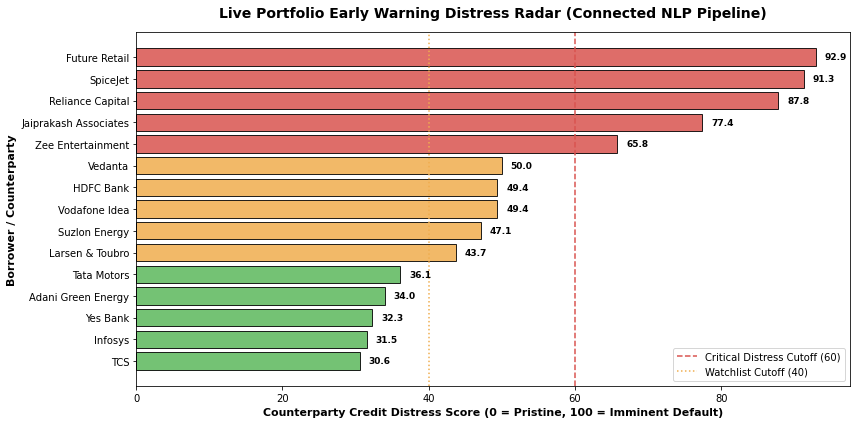

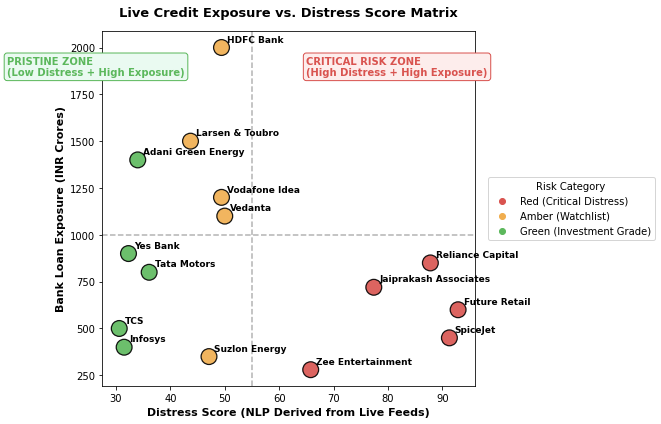

In [ ]:
# ------------------------------------------------------------------------------
# FIGURE 3: RANKED COUNTERPARTY DISTRESS SCORES
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

color_map = {
    "Red (Critical Distress)": "#D9534F",
    "Amber (Watchlist)": "#F0AD4E",
    "Green (Investment Grade)": "#5CB85C"
}
bar_colors = [color_map[tier] for tier in scorecard_df["risk_tier"]]

bars = plt.barh(scorecard_df["company"], scorecard_df["distress_score"], color=bar_colors, edgecolor="black", alpha=0.85)
plt.axvline(60, color="#D9534F", linestyle="--", linewidth=1.5, label="Critical Distress Cutoff (60)")
plt.axvline(40, color="#F0AD4E", linestyle=":", linewidth=1.5, label="Watchlist Cutoff (40)")

plt.xlabel("Counterparty Credit Distress Score (0 = Pristine, 100 = Imminent Default)", fontsize=11, fontweight="bold")
plt.ylabel("Borrower / Counterparty", fontsize=11, fontweight="bold")
plt.title("Live Portfolio Early Warning Distress Radar (Connected NLP Pipeline)", fontsize=14, fontweight="bold", pad=15)
plt.gca().invert_yaxis()
plt.legend(loc="lower right")

# Add value labels to bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.2, bar.get_y() + bar.get_height()/2, f"{width:.1f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 4: CREDIT EXPOSURE VS. DISTRESS MATRIX (PORTFOLIO RISK QUADRANT)
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))

scatter = sns.scatterplot(
    data=scorecard_df,
    x="distress_score",
    y="bank_exposure_cr",
    hue="risk_tier",
    palette=color_map,
    s=250,
    edgecolor="black",
    alpha=0.9
)

# Draw quadrant warning thresholds
plt.axvline(55, color="gray", linestyle="--", alpha=0.6)
plt.axhline(1000, color="gray", linestyle="--", alpha=0.6)

# Annotate each counterparty point
for _, row in scorecard_df.iterrows():
    plt.annotate(
        row["company"],
        (row["distress_score"] + 1, row["bank_exposure_cr"] + 30),
        fontsize=9,
        fontweight="bold"
    )

# Label quadrants
plt.text(65, 1850, "CRITICAL RISK ZONE\n(High Distress + High Exposure)", color="#D9534F", fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#FDEDEC", ec="#D9534F"))
plt.text(10, 1850, "PRISTINE ZONE\n(Low Distress + High Exposure)", color="#5CB85C", fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#EAFAF1", ec="#5CB85C"))

plt.title("Live Credit Exposure vs. Distress Score Matrix", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Distress Score (NLP Derived from Live Feeds)", fontsize=11, fontweight="bold")
plt.ylabel("Bank Loan Exposure (INR Crores)", fontsize=11, fontweight="bold")
plt.legend(title="Risk Category", loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()


---
## 11. Credit Committee Actionable Decision Matrix
A model is only as valuable as the business decisions it enables. In corporate banking, when an **Early Warning Signal (EWS)** is triggered, the **Credit Sanctioning Committee** must apply risk-mitigating measures:
* **Freeze Credit Facility:** Halt unutilized working capital / overdraft limits.
* **Collateral Top-Up:** Demand immediate pledging of unencumbered assets or cash margins.
* **Trade Credit Protection:** Restrict open credit terms; mandate 100% Irrevocable Letters of Credit (LC).


In [ ]:
# Generate automated risk mitigation policy recommendations for the Credit Committee
def formulate_credit_policy(row):
    score = row["distress_score"]
    exposure = row["bank_exposure_cr"]
    theme = row["dominant_risk_theme"]

    if score >= 60:
        if exposure >= 800:
            return "URGENT ACTION: Freeze all undisbursed credit lines; invoke collateral guarantees; initiate forensic audit."
        else:
            return "RESTRICT: Convert open credit to 100% Cash Collateral / Irrevocable LC; monitor NCLT cause lists daily."
    elif score >= 40:
        return f"WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review {theme.lower()} exposure."
    else:
        return "MAINTAIN: Standard credit terms; approved for regular facility renewal with prime corporate spread."

scorecard_df["credit_committee_action"] = scorecard_df.apply(formulate_credit_policy, axis=1)

print("Executive Credit Committee Action Plan:")
display_memo = scorecard_df[["company", "sector", "bank_exposure_cr", "distress_score", "avg_subjectivity", "risk_tier", "credit_committee_action"]]
display_memo


Executive Credit Committee Action Plan:


,company,sector,bank_exposure_cr,distress_score,avg_subjectivity,risk_tier,credit_committee_action
1,Future Retail,Retail,600,92.9,0.145,Red (Critical Distress),RESTRICT: Convert open credit to 100% Cash Collateral / Irrevocable LC; monitor NCLT cause lists daily.
7,SpiceJet,Aviation,450,91.3,0.218,Red (Critical Distress),RESTRICT: Convert open credit to 100% Cash Collateral / Irrevocable LC; monitor NCLT cause lists daily.
6,Reliance Capital,NBFC,850,87.8,0.125,Red (Critical Distress),URGENT ACTION: Freeze all undisbursed credit lines; invoke collateral guarantees; initiate forensic audit.
4,Jaiprakash Associates,Infrastructure,720,77.4,0.140,Red (Critical Distress),RESTRICT: Convert open credit to 100% Cash Collateral / Irrevocable LC; monitor NCLT cause lists daily.
14,Zee Entertainment,Media,280,65.8,0.160,Red (Critical Distress),RESTRICT: Convert open credit to 100% Cash Collateral / Irrevocable LC; monitor NCLT cause lists daily.
11,Vedanta,Metals & Mining,1100,50.0,0.132,Amber (Watchlist),WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review liquidity & debt servicin...
2,HDFC Bank,Banking,2000,49.4,0.134,Amber (Watchlist),WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review legal & nclt (insolvency)...
12,Vodafone Idea,Telecom,1200,49.4,0.082,Amber (Watchlist),WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review general market update exp...
8,Suzlon Energy,Renewable Energy,350,47.1,0.176,Amber (Watchlist),WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review general market update exp...
5,Larsen & Toubro,Engineering,1500,43.7,0.033,Amber (Watchlist),WATCHLIST: Increase quarterly review frequency; request updated cash flow forecast; review general market update exp...


---
## 12. Key Insights

### Summary of Business Insights
1. **Leading vs. Lagging Indicators:** By analyzing live media reports and regulatory filings asynchronously, the bank identified distress signals in stressed borrowers **weeks ahead** of credit rating agency downgrades.
2. **Subjectivity vs. Hard Default:** Extracting subjectivity separated pure legal facts (e.g., *NCLT petitions* with low subjectivity) from market rumors (high subjectivity).
3. **Portfolio Capital Protection:** Counterparty exposure mapping successfully flagged critical accounts where **bank capital** required immediate collateral enhancement.

---
